# Reading a Triangle / TetGen mesh

**Triangle** (Shewchuk) is the classic 2-D quality mesh generator; **TetGen** is its 3-D tetrahedral counterpart, and both use the same `.node` (points) + `.ele` (elements) file pair. You point `read_file` at the **`.node`** file and the driver pulls in the matching `.ele`. `pyramids-mesh` returns a `pyramids.netcdf.ugrid.UgridDataset`.

This sample is meshio's TetGen test mesh — a **3-D tetrahedral** mesh (89 nodes, 304 tetrahedra), which makes it a good illustration of what happens when a genuinely 3-D volume mesh meets 2-D planar GIS operations (MIT-licensed data).

## 1. Set up the plotting backend

We render through `cleopatra`/`matplotlib`. To execute identically in CI and interactively we pin the non-interactive **`Agg`** backend *before* importing `pyplot`, and define a tiny `show()` helper that writes the current figure straight into the notebook as a PNG. Call `show()` after every plot.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib; matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight"); plt.close("all"); buf.seek(0)
    display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd

## 3. Locate the example data

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths inside a notebook are written **relative to the notebook itself**. The critical rule for `read_file` is to pass a `pathlib.Path`, never `str(...)`. We read `triangle/mesh.node`.

In [3]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "triangle" / "mesh.node"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/triangle/mesh.node'), True)

## 4. Quickstart: read the file

`UgridDataset.read_file(path, driver=...)` parses the file and returns a `UgridDataset` — the same type pyramids produces from a NetCDF UGRID file. We name the `"triangle"` driver explicitly; passing the **`Path`** object (not a string) is the supported call.

In [4]:
ds = UgridDataset.read_file(mesh_file, driver="triangle")
type(ds).__name__

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 144 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 10 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


'UgridDataset'

## 5. Explore the dataset

A `UgridDataset` exposes summary properties: `n_node` / `n_face` (mesh size), `crs` / `epsg` (georeferencing if the format recorded any), `bounds` (the `(minx, miny, maxx, maxy)` extent), and `data_variable_names` (attached field variables).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": tuple(round(float(b), 3) for b in ds.bounds),
    "data_variable_names": ds.data_variable_names,
})

n_node                                   89
n_face                                  304
crs                                    None
epsg                                   None
bounds                 (0.0, 0.0, 1.0, 1.0)
data_variable_names                [node_z]
dtype: object

`crs`/`epsg` are `None` — a mesh generator emits raw coordinates. Note `data_variable_names` contains **`node_z`**: this is a 3-D mesh, so the z-coordinate rides along as a nodal field. The `bounds` report only the x/y extent (the unit cube's footprint).

## 6. Face-degree distribution

`ds.mesh.face_node_connectivity.data` is the `(n_face, k)` table of node indices per face, where `k` is the widest polygon. Cells with fewer nodes than `k` are **padded with `-1` (fill)**. Counting the non-negative entries per row gives each face's number of nodes — its *degree*.

In [6]:
conn = np.asarray(ds.mesh.face_node_connectivity.data)
degree = (conn >= 0).sum(axis=1)
vals, counts = np.unique(degree, return_counts=True)
dist = pd.Series(dict(zip(vals.tolist(), counts.tolist())), name="n_faces")
dist.index.name = "nodes_per_face"
{"degree_distribution": dist.to_dict(), "fill_slots(-1)": int((conn == -1).sum())}

{'degree_distribution': {4: 304}, 'fill_slots(-1)': 0}

Every cell has **4 nodes** with no `-1` fill — these are **tetrahedra** (4 vertices each), not triangles. The `.node`/`.ele` pair happens to be the TetGen 3-D variant; a 2-D Triangle mesh would instead show degree-3 triangular cells here.

## 7. The underlying geometry

`ds.mesh` is the `Mesh2d` holding the raw arrays: `node_x` / `node_y` (coordinates), the connectivity table, `face_areas` (one area per cell) and `face_centroids` (shape `(2, n_face)`). Everything geometric is derived from the connectivity plus the node coordinates.

In [7]:
mesh = ds.mesh
conn = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
cent = np.asarray(mesh.face_centroids)  # (2, n_face)
{"conn_shape": conn.shape, "n_node": np.asarray(mesh.node_x).shape[0],
 "areas_minmax": (round(float(areas.min()), 4), round(float(areas.max()), 4)),
 "centroids_shape": cent.shape}

{'conn_shape': (304, 4),
 'n_node': 89,
 'areas_minmax': (0.0, 0.1028),
 'centroids_shape': (2, 304)}

Because the cells are tetrahedra projected onto the x/y plane, some faces collapse to near-zero area — visible as a `0.0` minimum above. That is expected for a 3-D mesh viewed through a 2-D area computation.

## 8. Wireframe: `plot_outline()`

The simplest view needs no data — just the mesh edges. `plot_outline()` draws the wireframe through cleopatra; `show()` embeds it. This is the fastest sanity check that a file read in correctly.

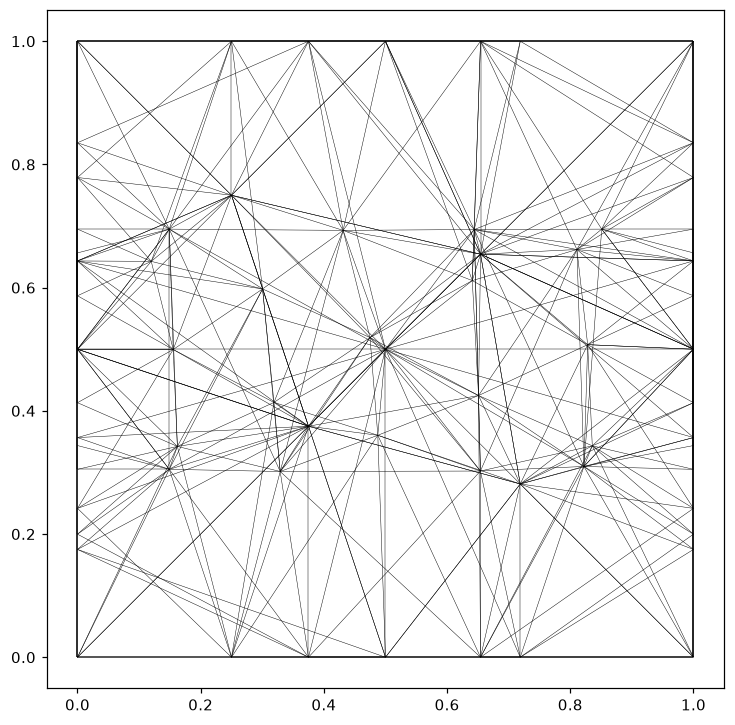

In [8]:
ds.plot_outline()
show()

The outline is the 2-D projection (shadow) of the 3-D tetrahedral mesh onto the x/y plane — overlapping triangles where tetrahedra stack in z. It renders, but remember you are looking at a flattened volume.

## 9. A data map: attach and colour a field

To draw a *filled* map we need a value per cell. These mesh files carry geometry only, so we compute one — each cell's area — and attach it with `with_variable(..., location="face")`, which returns a **new** dataset (the original `ds` is untouched). Then `plot` colours the mesh by it.

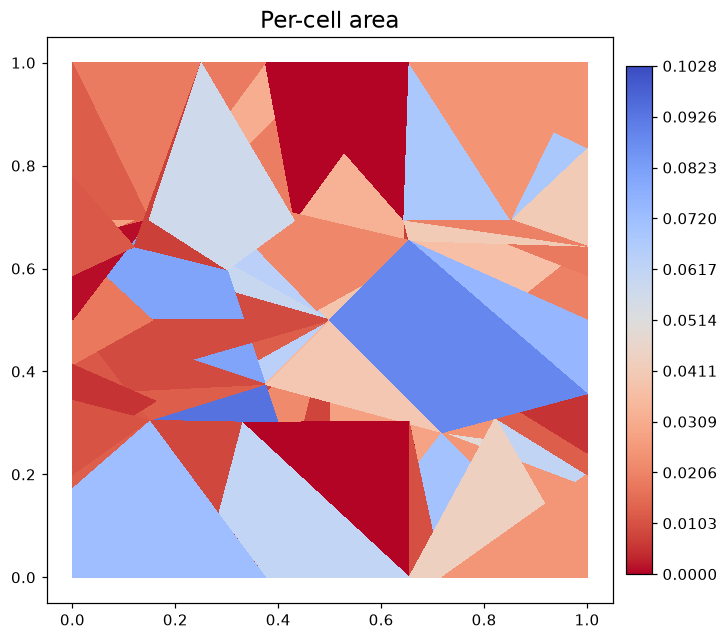

In [9]:
d2 = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="Per-cell area")
show()

Each cell is now shaded by its area. This is the generic pyramids data-map path — any per-cell field (water depth, velocity, head) plots exactly the same way.

### The statistical summary

With a field attached, `.summary()` reports per-variable statistics (count, min, max, mean, std). On the bare `ds` it is an empty frame; on `d2` it has a real row.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
node_z,89,0.0,1.000000,0.488156,0.297577
cell_area,304,0.0,0.102842,0.024193,0.021642


## 10. GIS operations, for free

Because the mesh is now a first-class pyramids object, the pyramids GIS layer applies directly — `pyramids-mesh` itself adds none of this. The next cells each run one operation and interpret it.

### Faces as a GeoDataFrame

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((0.30048 0.59789, 0.16212 0.34222, 0...."
1,"POLYGON ((0.82821 0.5074, 0.81073 0.66186, 0.6..."
2,"POLYGON ((0.16212 0.34222, 0.32907 0.30152, 0...."
3,"POLYGON ((0.31894 0.41364, 0.32907 0.30152, 0...."
4,"POLYGON ((0 0.5, 0.16212 0.34222, 0.15537 0.49..."


Plotting that GeoDataFrame draws the mesh footprint as vector polygons (one patch per cell).

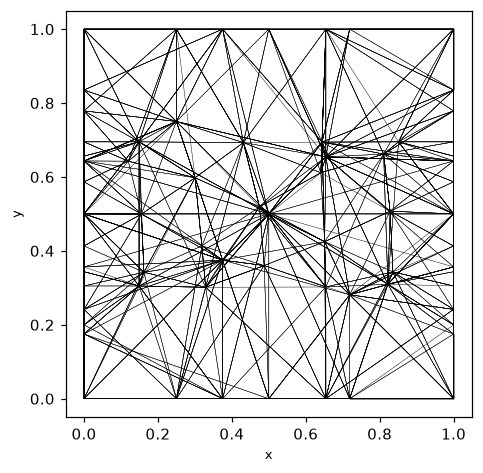

In [12]:
gdf.plot(edgecolor="black", facecolor="none", linewidth=0.3)
show()

### Bounding polygon — explain and skip

`bounding_polygon()` dissolves the cells into one shapely polygon. On **this** mesh it raises a GEOS `TopologyException` — the projected tetrahedra overlap, so dissolving them produces a self-intersecting (invalid) geometry. We therefore skip it and fall back to the numeric `bounds` extent.

In [13]:
try:
    ds.bounding_polygon()
except Exception as e:
    print("skipped bounding_polygon:", type(e).__name__)
tuple(round(float(b), 3) for b in ds.bounds)

skipped bounding_polygon: GEOSException


(0.0, 0.0, 1.0, 1.0)

### Circumcenters — explain and skip

`circumcenters()` is **only defined for triangular meshes**. This mesh is not all-triangle, so the call raises `ValueError`; we catch it rather than crash. (Use cell centroids instead for such grids.)

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped circumcenters:", e)

skipped circumcenters: circumcenters is only defined for triangular meshes.


### Exterior edges

`exterior_edges()` returns the node indices of the mesh **boundary** — the edges that belong to exactly one cell. Its length is a quick measure of how much perimeter the mesh has.

In [15]:
edges = np.asarray(ds.exterior_edges())
edges.shape, edges[:6].tolist()

((84,), [20, 43, 70, 72, 82, 84])

`exterior_edges()` returns the boundary of the projected footprint. Because the mesh is a flattened 3-D volume, this perimeter is the silhouette of the tetrahedral block, not a clean 2-D domain boundary.

### Cell adjacency and connected components

`sparse_adjacency()` is the cell-to-cell adjacency as a SciPy sparse matrix (`nnz` = twice the number of shared internal edges). `connected_components()` labels which cells are mutually reachable through that adjacency.

In [16]:
adj = ds.sparse_adjacency()
labels = np.asarray(ds.connected_components())
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(labels).size)}

{'adjacency_shape': (304, 304), 'nnz': 660, 'n_components': 29}

`connected_components()` reports **many** components: once tetrahedra are flattened to 2-D cells, many no longer share full edges, so the 2-D adjacency graph fragments. This is the tell-tale sign of forcing a 3-D volume mesh through 2-D planar topology.

### Subset by a bounding box

`subset_by_bounds(xmin, ymin, xmax, ymax)` keeps only the cells inside a window (note the four positional coordinates, not a tuple). We take the centred 60% window and plot the result — a clean clip that returns a new `UgridDataset`. (`crop(bbox=...)` does the same thing with a tuple argument.)

In [17]:
b = ds.bounds
cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
hx, hy = (b[2] - b[0]) * 0.3, (b[3] - b[1]) * 0.3
sub = ds.subset_by_bounds(cx - hx, cy - hy, cx + hx, cy + hy)
{"full_n_face": ds.n_face, "subset_n_face": sub.n_face}

{'full_n_face': 304, 'subset_n_face': 105}

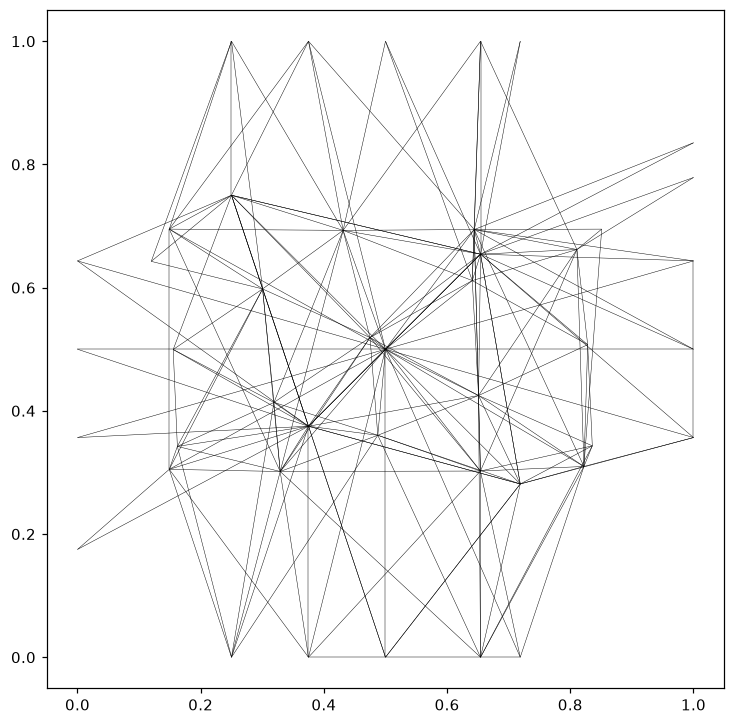

In [18]:
sub.plot_outline()
show()

The box-subset still works on the projected footprint — it keeps whichever flattened cells fall in the window. Treat the result as a 2-D slice of the projection rather than a volumetric clip.

### Export: xarray and NetCDF round-trip

`to_xarray()` hands back an `xarray.Dataset` (the UGRID representation), and `to_file(path)` writes a NetCDF UGRID file — the canonical pyramids on-disk form that any UGRID reader can load back.

In [19]:
import tempfile, os
xds = ds.to_xarray()
out = os.path.join(tempfile.gettempdir(), "mesh_roundtrip.nc")
ds.to_file(out)
{"xarray_type": type(xds).__name__, "nc_bytes": os.path.getsize(out)}

{'xarray_type': 'Dataset', 'nc_bytes': 20064}

## 11. CRS-dependent operations — explain and skip

This format records **no CRS** (`crs` / `epsg` were `None` above), so coordinate-aware steps have nothing to work from:

- **`to_crs(...)`** — a reprojection needs a *source* CRS; with `None` there is nothing to reproject from, so we skip it. In practice you would first assign the CRS you know the model used.
- **`rasterize_like(...)` / `regrid(...)`** — these burn the mesh onto, or resample it to, a target **raster grid**. That is the job of the `pyramids-gis` raster layer (you supply a target `Dataset`); it is out of scope for a format-reader tutorial, so we only name it here.

In [20]:
ds.crs  # None -> no reprojection target; to_crs / rasterize_like / regrid skipped

## 12. Takeaway

- **Triangle/TetGen = the `.node` + `.ele` pair** from a 2-D/3-D mesh generator; point `read_file` at the `.node` file.
- This sample is a **3-D tetrahedral** mesh (degree-4 cells, a `node_z` field), not a flat triangulation.
- 2-D planar ops degrade gracefully on a projected volume: `circumcenters()` (non-triangular) and `bounding_polygon()` (self-intersecting projection) are skipped, and the adjacency fragments into many components — all expected, all caught rather than crashing.
- The read, explore, wireframe, cell-area map and box-subset still work on the projected mesh.